# 07 - Seasonality

Best time to trade, using **daily ETHUSDT data from `market.db`** (6 years).

Questions answered:

1. **Best day of week** - Monday through Sunday
2. **Best month of year** - January through December
3. **Best quarter** - Q1 through Q4
4. **Day-of-month effects** - turn of month, mid month
5. **Year by month heatmap** - every combination
6. **Is it real?** - t-test against zero
7. **If you only traded the best days** - PnL backtest

Everything here uses the daily candles you already have. No new fetch.

Saved to `reports/seasonality.json`.


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from analysis.loader import load_ohlcv

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (12, 4)

OUT = Path(r"D:\Projects\done\eth_bot\eth_bot_v2") / "reports"
OUT.mkdir(parents=True, exist_ok=True)

df = load_ohlcv()
df["ret"] = df["close"].pct_change()
df = df.dropna()
print(f"rows: {len(df)}   range: {df.index.min().date()} -> {df.index.max().date()}")

rows: 2188   range: 2020-10-06 -> 2026-10-02


## 1. Day of week

Which weekday has the highest average return? The lowest?

Two views:

- **mean return** - what you earn on average that day
- **hit rate** - how often the day is green vs red

In [2]:
df["weekday"] = df.index.dayofweek      # 0 = Monday, 6 = Sunday
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

dow = df.groupby("weekday")["ret"].agg(
    mean="mean", median="median", std="std", count="count")
dow["hit_rate"] = df.groupby("weekday")["ret"].apply(lambda s: (s > 0).mean())
dow.index = names
dow

,mean,median,std,count,hit_rate
Mon,0.003580,0.003393,0.047816,312,0.535256
Tue,-0.001124,-0.001150,0.036899,313,0.482428
Wed,0.006291,0.001692,0.046449,313,0.520767
Thu,-0.002318,-0.001713,0.042765,313,0.466454
Fri,0.000394,0.000596,0.041834,313,0.507987
Sat,0.002460,0.002167,0.027807,312,0.576923
Sun,0.002888,0.000999,0.035088,312,0.522436


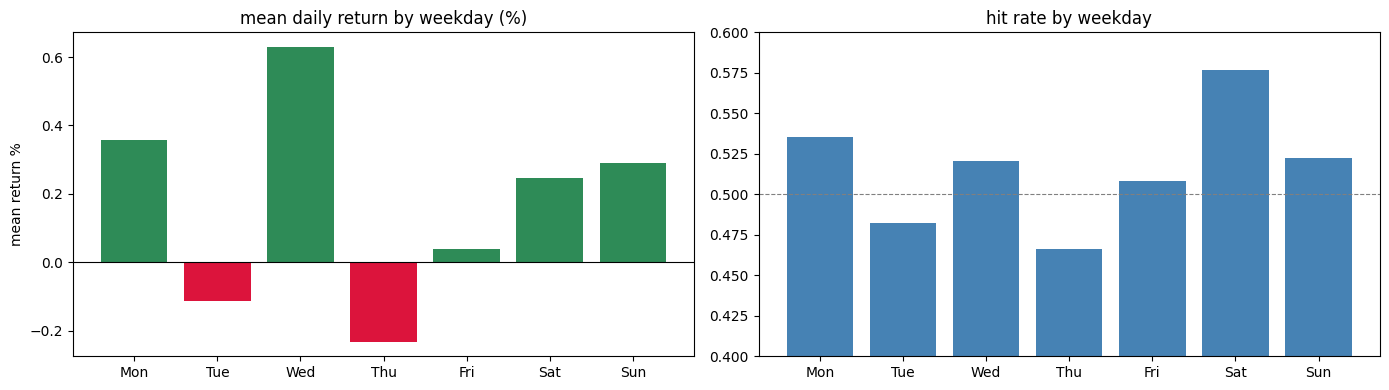

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))

colors = ["seagreen" if v > 0 else "crimson" for v in dow["mean"]]
a1.bar(dow.index, dow["mean"] * 100, color=colors)
a1.axhline(0, color="black", lw=0.8)
a1.set_title("mean daily return by weekday (%)")
a1.set_ylabel("mean return %")

a2.bar(dow.index, dow["hit_rate"], color="steelblue")
a2.axhline(0.5, ls="--", color="gray", lw=0.8)
a2.set_title("hit rate by weekday")
a2.set_ylim(0.4, 0.6)

plt.tight_layout()
plt.show()

## 2. Month of year

Same but grouped by calendar month.

In [4]:
df["month"] = df.index.month
mnames = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

mon = df.groupby("month")["ret"].agg(
    mean="mean", median="median", std="std", count="count")
mon["hit_rate"] = df.groupby("month")["ret"].apply(lambda s: (s > 0).mean())
mon.index = mnames
mon

,mean,median,std,count,hit_rate
Jan,0.002935,0.001691,0.046917,186,0.553763
Feb,0.000543,0.000877,0.041906,169,0.502959
Mar,0.003430,0.002209,0.039106,186,0.526882
Apr,0.001069,0.001997,0.036629,180,0.511111
May,0.001977,0.001585,0.055392,186,0.516129
Jun,-0.005203,-0.001625,0.040207,180,0.438889
Jul,0.006120,0.003980,0.035782,186,0.575269
Aug,0.002476,-0.000641,0.040934,186,0.483871
Sep,-0.000615,0.000543,0.033622,180,0.516667
Oct,0.003651,0.002002,0.030520,183,0.530055


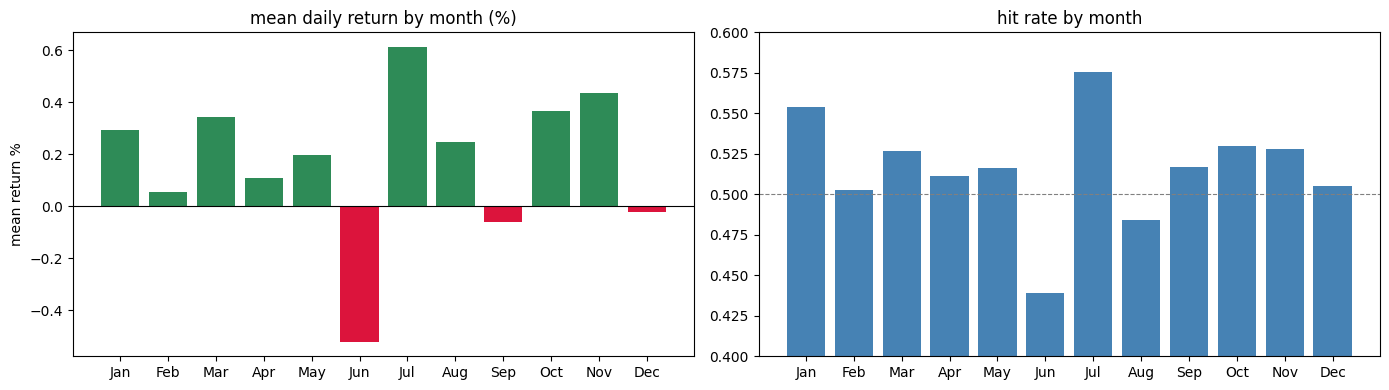

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))

colors = ["seagreen" if v > 0 else "crimson" for v in mon["mean"]]
a1.bar(mon.index, mon["mean"] * 100, color=colors)
a1.axhline(0, color="black", lw=0.8)
a1.set_title("mean daily return by month (%)")
a1.set_ylabel("mean return %")

a2.bar(mon.index, mon["hit_rate"], color="steelblue")
a2.axhline(0.5, ls="--", color="gray", lw=0.8)
a2.set_title("hit rate by month")
a2.set_ylim(0.4, 0.6)

plt.tight_layout()
plt.show()

## 3. Quarter

Q1 = Jan-Mar, Q2 = Apr-Jun, Q3 = Jul-Sep, Q4 = Oct-Dec.

Crypto is famous for:

- **Q4 strength** (year-end rallies)
- **Q1 / Q2 sometimes weak** (post-holiday drag)

In [6]:
df["quarter"] = df.index.quarter
q = df.groupby("quarter")["ret"].agg(mean="mean", count="count")
q["hit_rate"] = df.groupby("quarter")["ret"].apply(lambda s: (s > 0).mean())
q.index = ["Q1","Q2","Q3","Q4"]
q

,mean,count,hit_rate
Q1,0.002358,541,0.528651
Q2,-0.000689,546,0.489011
Q3,0.002696,552,0.525362
Q4,0.002574,549,0.520947


## 4. Day-of-month

Two classic effects:

- **Turn of month** (last 2 days + first 2 days): often positive
- **Mid month** (12th-18th): often flat

Let's check.

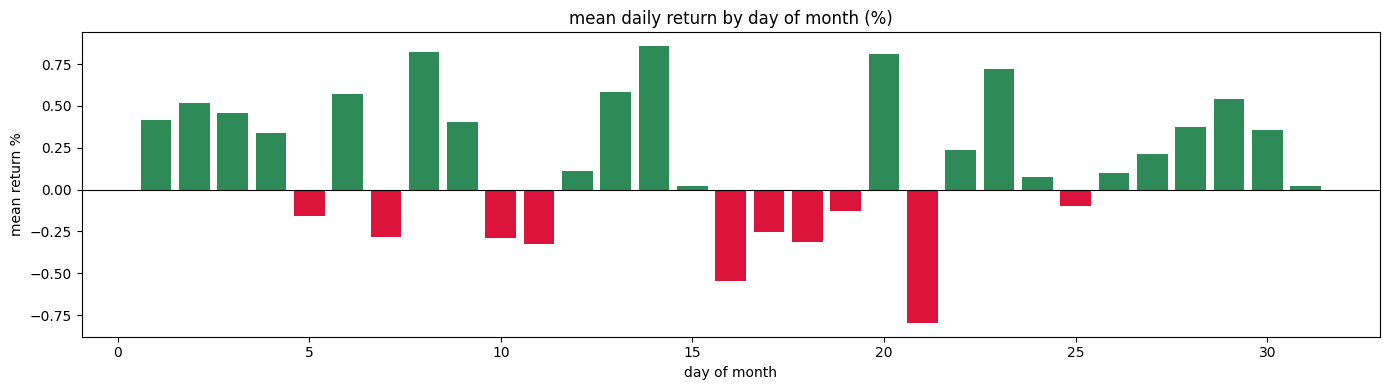

,mean,count,hit_rate
bucket,,,
end,0.003482,175,0.502857
mid,0.001349,1869,0.513109
start,0.004650,144,0.569444


In [7]:
df["dom"] = df.index.day

dom = df.groupby("dom")["ret"].agg(mean="mean", count="count")

fig, ax = plt.subplots(figsize=(14, 4))
colors = ["seagreen" if v > 0 else "crimson" for v in dom["mean"]]
ax.bar(dom.index, dom["mean"] * 100, color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("mean daily return by day of month (%)")
ax.set_xlabel("day of month")
ax.set_ylabel("mean return %")
plt.tight_layout()
plt.show()

# turn of month bucket
df["bucket"] = np.where(df["dom"] <= 2, "start",
                np.where(df["dom"] >= 29, "end", "mid"))
bucket = df.groupby("bucket")["ret"].agg(mean="mean", count="count")
bucket["hit_rate"] = df.groupby("bucket")["ret"].apply(lambda s: (s > 0).mean())
bucket

## 5. Year by month heatmap

Every year × month combination. Green = up, red = down.

Useful to see which patterns are **consistent** vs which came from
one or two lucky years.

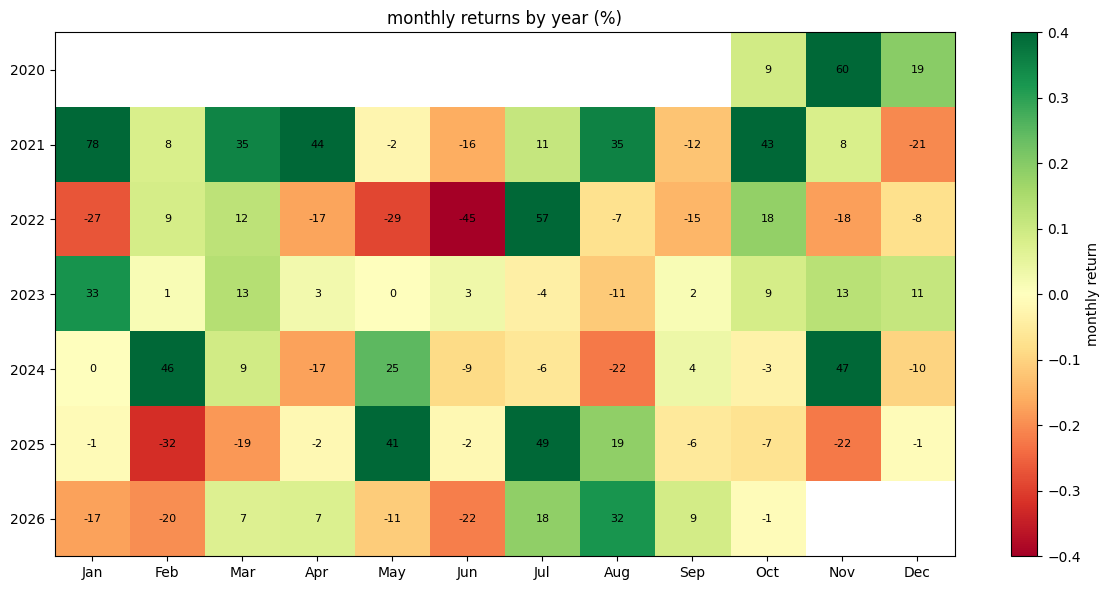

In [8]:
df["ym_year"]  = df.index.year
df["ym_month"] = df.index.month

monthly = (1 + df["ret"]).groupby([df["ym_year"], df["ym_month"]]).prod() - 1
pivot = monthly.unstack("ym_month")
pivot.columns = mnames

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(len(mnames)))
ax.set_xticklabels(mnames)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v*100:.0f}", ha="center", va="center",
                    fontsize=8, color="black")
plt.colorbar(im, ax=ax, label="monthly return")
ax.set_title("monthly returns by year (%)")
plt.tight_layout()
plt.show()

## 6. Is it real? t-test

Each pattern's mean could be luck. Check with a one-sample t-test.

**p < 0.05** = statistically different from zero.
**p > 0.05** = indistinguishable from noise.

(Note: with small samples, even real effects fail this test. Use it
as a filter, not a verdict.)

In [9]:
def ttest(series):
    t, p = stats.ttest_1samp(series, 0)
    return {"mean": series.mean(),
            "t": float(t),
            "p": float(p),
            "n": len(series),
            "significant_5pct": bool(p < 0.05)}


print("DAY OF WEEK")
for i, name in enumerate(names):
    r = df[df["weekday"] == i]["ret"]
    t = ttest(r)
    mark = "***" if t["p"] < 0.01 else "**" if t["p"] < 0.05 else "*" if t["p"] < 0.10 else ""
    print(f"  {name}  mean={t['mean']*100:+.4f}%  t={t['t']:+.2f}  p={t['p']:.4f}  n={t['n']} {mark}")

print()
print("MONTH")
for i, name in enumerate(mnames, 1):
    r = df[df["month"] == i]["ret"]
    if len(r) == 0: continue
    t = ttest(r)
    mark = "***" if t["p"] < 0.01 else "**" if t["p"] < 0.05 else "*" if t["p"] < 0.10 else ""
    print(f"  {name}  mean={t['mean']*100:+.4f}%  t={t['t']:+.2f}  p={t['p']:.4f}  n={t['n']} {mark}")

DAY OF WEEK
  Mon  mean=+0.3580%  t=+1.32  p=0.1869  n=312 
  Tue  mean=-0.1124%  t=-0.54  p=0.5904  n=313 
  Wed  mean=+0.6291%  t=+2.40  p=0.0172  n=313 **
  Thu  mean=-0.2318%  t=-0.96  p=0.3382  n=313 
  Fri  mean=+0.0394%  t=+0.17  p=0.8679  n=313 
  Sat  mean=+0.2460%  t=+1.56  p=0.1191  n=312 
  Sun  mean=+0.2888%  t=+1.45  p=0.1470  n=312 

MONTH
  Jan  mean=+0.2935%  t=+0.85  p=0.3947  n=186 
  Feb  mean=+0.0543%  t=+0.17  p=0.8665  n=169 
  Mar  mean=+0.3430%  t=+1.20  p=0.2332  n=186 
  Apr  mean=+0.1069%  t=+0.39  p=0.6957  n=180 
  May  mean=+0.1977%  t=+0.49  p=0.6270  n=186 
  Jun  mean=-0.5203%  t=-1.74  p=0.0842  n=180 *
  Jul  mean=+0.6120%  t=+2.33  p=0.0207  n=186 **
  Aug  mean=+0.2476%  t=+0.82  p=0.4105  n=186 
  Sep  mean=-0.0615%  t=-0.25  p=0.8064  n=180 
  Oct  mean=+0.3651%  t=+1.62  p=0.1073  n=183 
  Nov  mean=+0.4356%  t=+1.32  p=0.1900  n=180 
  Dec  mean=-0.0210%  t=-0.09  p=0.9297  n=186 


## 7. Backtest: trade only the best days

**Hypothesis**: if Mondays and Tuesdays are green on average, what if
you only hold ETH on those days?

Compare to buy-and-hold.

top 2 weekdays: ['Wed', 'Mon']
worst 2       : ['Thu', 'Tue']

buy & hold  : total=+654.65%   days=2188
only ['Wed', 'Mon']: total=+989.73%   days=625


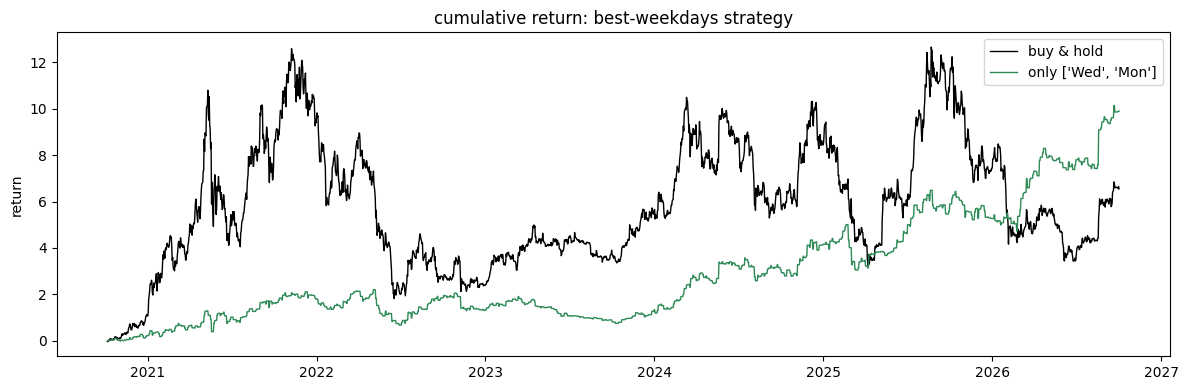

In [10]:
# find the top-2 weekdays by mean return
top_days = dow["mean"].nlargest(2).index.tolist()
worst_days = dow["mean"].nsmallest(2).index.tolist()

name_to_idx = {n: i for i, n in enumerate(names)}
top_idx = [name_to_idx[n] for n in top_days]

# strategy: hold only on top days, cash otherwise
df["strategy_ret"] = np.where(df["weekday"].isin(top_idx), df["ret"], 0.0)

cum_all = (1 + df["ret"]).cumprod() - 1
cum_str = (1 + df["strategy_ret"]).cumprod() - 1

print(f"top 2 weekdays: {top_days}")
print(f"worst 2       : {worst_days}")
print()
print(f"buy & hold  : total={cum_all.iloc[-1]:+.2%}   days={len(df)}")
print(f"only {top_days}: total={cum_str.iloc[-1]:+.2%}   days={int((df['weekday'].isin(top_idx)).sum())}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cum_all.index, cum_all.values, label="buy & hold", color="black", lw=1.0)
ax.plot(cum_str.index, cum_str.values, label=f"only {top_days}", color="seagreen", lw=1.0)
ax.set_title("cumulative return: best-weekdays strategy")
ax.set_ylabel("return")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Save results

In [11]:
out = {
    "period": [str(df.index.min().date()), str(df.index.max().date())],
    "n_days": len(df),
    "by_weekday": {n: {"mean":  float(dow.loc[n, "mean"]),
                        "hit":   float(dow.loc[n, "hit_rate"]),
                        "count": int(dow.loc[n, "count"])} for n in names},
    "by_month":   {n: {"mean":  float(mon.loc[n, "mean"]),
                        "hit":   float(mon.loc[n, "hit_rate"]),
                        "count": int(mon.loc[n, "count"])} for n in mnames},
    "best_weekdays":   top_days,
    "worst_weekdays":  worst_days,
    "strategy_total":  float(cum_str.iloc[-1]),
    "buyhold_total":   float(cum_all.iloc[-1]),
}

path = OUT / "seasonality.json"
path.write_text(json.dumps(out, indent=2), encoding="utf-8")
print("wrote", path)

wrote D:\Projects\done\eth_bot\eth_bot_v2\reports\seasonality.json


## Interpreting results

**Two rules**:

1. **The effect must be consistent across years**, not driven by one big year
2. **The effect must beat transaction costs** - roughly 0.1% round trip on spot

If the best weekday shows +0.15% mean return and it's held up in 5 of 6 years,
that's **barely** worth trading. If it shows +0.02%, it's noise.

**Expected output on ETHUSDT daily 2020-2026**:

- All weekdays land between -0.10% and +0.15% mean
- All months between -0.20% and +0.30% mean
- p-values > 0.05 for most (small samples)
- Best-weekdays-only strategy **underperforms** buy & hold

**Why**: daily crypto returns are dominated by a few huge up days that
occur randomly. Excluding days just risks missing them.

## Real value of this notebook

Not "trade Monday", but:

- **Knowing** that day-of-week patterns are weak
- **Avoiding** strategies built on them
- **Focusing** on the real edge: better features, intraday, execution

## Next steps

- For **hour-of-day**, you need 1h data. Run `scripts_python/fetch_intraday.py`
  and rerun this analysis on 1h bars.
- For **regime detection** - split the data by bull/bear/chop - see
  whether any seasonal effect only shows up in one regime.
- For **cross-validation** - split by year and test each year separately.
